# 8 · Knowledge-graph visualization  (per article)

Draws the KG produced by the pipeline for one article in two forms, both written under
`results/<model>/<id>/<track>/viz/`:

- **`kg.png`** — a static matplotlib/networkx figure for the thesis: component-packed layout
  (the connected graph on the left, everything relation-less in a labelled side panel), wrapped
  labels with a halo, and a label-aware de-overlap pass so nothing collides.
- **`kg.html`** — a **self-contained interactive viewer** (§4): filters by vocabulary source,
  node type, structure and confidence; three colour modes; three layouts; a details panel with each
  node/edge's full record; and a triples table. Opens offline, nothing is fetched.

The loader **auto-detects** the graph shape from the file named in `REL_FILES`:

- **Binary** (`relations_ext*.json`, nb7) — entities as nodes, `subject → property → object` triples
  as edges. Nodes coloured by **entity type**; edges **solid** for schema.org properties, **dashed**
  for minted `ex:` properties.
- **Reified / event-centric** (`nary_graph*.json`, nb6b/6c) — the **n-ary nodes** (Event / Observation /
  Claim) become **★ star nodes** coloured by node kind, with **main events outlined**; each relation
  is an edge n-ary-node→participant labelled with the property and **dashed for minted `ex:`** terms,
  solid for schema.org ones. The old `hubs` + roles schema (with `value_text` literals, toggled by
  `INCLUDE_LITERALS`) still loads.

Throughout, one vocabulary language applies to both properties and types:
**schema.org** · **vocab / minted (`ex:`)** · **open** (not yet canonicalized).

Switch views by editing `REL_FILES` in the config cell — everything below works unchanged for both.

In [70]:
# --- resolve Phase2_LLM_Extraction root (works whether this notebook lives at the
# project root or under notebooks/<track>/) so results/ & dataset/ paths are stable.
from pathlib import Path
def _find_root(start: Path = None):
    start = (start or Path.cwd()).resolve()
    for p in (start, *start.parents):
        if (p / 'results').is_dir() and (p / 'dataset').is_dir():
            return p
    return start
ROOT = _find_root()
# make Path writes create missing parent dirs (results/ now has sub-folders like
# two_staged/1_entities/); guarded so re-running the cell never double-wraps.
import pathlib as _pl
if not getattr(_pl.Path.write_text, '_mkparents', False):
    _wt, _wb = _pl.Path.write_text, _pl.Path.write_bytes
    def write_text(self, *a, **k):
        self.parent.mkdir(parents=True, exist_ok=True); return _wt(self, *a, **k)
    def write_bytes(self, *a, **k):
        self.parent.mkdir(parents=True, exist_ok=True); return _wb(self, *a, **k)
    write_text._mkparents = write_bytes._mkparents = True
    _pl.Path.write_text, _pl.Path.write_bytes = write_text, write_bytes

In [71]:
# ---- WHICH MODEL'S RESULTS ---------------------------------------------------------------
# Everything is read from and written to results/<RESULTS_MODEL>/. Choose any subfolder that
# exists there: "gemini-2.5-flash", "qwen3-14b", "qwen3-32b", "llama33-70b", ... (the names are
# the BACKENDS keys in notebooks/llm_backend.py).
RESULTS_MODEL = "gemini-2.5-flash"
# ------------------------------------------------------------------------------------------

# --- Config -------------------------------------------------------------------------------
from pathlib import Path

RESULTS_DIR = ROOT / "results" / RESULTS_MODEL   # per-article outputs from nb6b (n-ary) or nb7 (binary)
ARTICLE_ID  = "art2"              # which article to draw

# Which graph file to read. The loader AUTO-DETECTS the shape:
#   - nary_graph.json (nb6b)     -> n-ary nodes + open `relations` (relation_phrase)  [event-centric view]
#   - relations_ext*.json (nb7)  -> flat subject/property/object triples              [binary view]
# List them in priority order; the first that exists per article wins.
#   n-ary:   REL_FILES = ["two_staged/3_nary_graph/nary_graph.json"]
#   binary:  REL_FILES = ["two_staged/2_binary_relations/relations_consolidated.json", "two_staged/2_binary_relations/relations.json"]
REL_FILES = ["e2e/nary_graph_dedup_rr_orig2_mixedCons_extended_consolidated.json"]


INCLUDE_ISOLATED = True           # False: only nodes that take part in >=1 edge (clearer graph)
SHOW_NORMALIZED_TIME = True       # append a temporal entity's resolved date (normalized_value[->end]) to its label + tooltip
INCLUDE_LITERALS = True           # (reified only) draw value_text-only roles as small box nodes — old schema
MAX_TYPE_COLORS  = 8              # distinct type colours; rarer types fold into a neutral "Other"
SHOW_EDGE_LABELS = True           # STATIC figure: draw the property on each edge (auto-off above EDGE_LABEL_MAX)
STATIC_FIGSIZE   = (16, 11)       # base size; the figure grows with the node count
LAYOUT_SEED      = 42             # reproducible spring layout

# The INTERACTIVE viewer has no config here on purpose — spacing, label size, layout, filters and
# colour mode are all controls inside the generated HTML (see §4).

def rel_path(aid):
    for name in REL_FILES:
        p = RESULTS_DIR / aid / name
        if p.exists():
            return p
    return None

print("article:", ARTICLE_ID, "| reads first present of:", REL_FILES)

article: art2 | reads first present of: ['e2e/nary_graph_dedup_rr_orig2_mixedCons_extended_consolidated.json']


In [72]:
# First run only.
%pip install -q networkx matplotlib pyvis

Note: you may need to restart the kernel to use updated packages.


## 1. Load the graph (self-contained from nb7's relations file)

In [73]:
import json
from collections import Counter

LAST_SRC = ""     # basename of the file the most recent load_kg() read — drives the output filename (kg_stem)

def _fmt_norm(c):
    """Compact resolved date for a temporal entity: normalized_value, or start→end for a span."""
    nv = c.get("normalized_value")
    if not nv: return None
    ne = c.get("normalized_end")
    return f"{nv}→{ne}" if (ne and ne != nv) else nv

# Every node/edge keeps a "raw" pointer to the record it came from, so the interactive viewer can show
# the FULL card (definition, justification, parent term, evidence, confidence) in its details panel.

def load_binary(data, cards, include_isolated):
    """nb7 flat relations -> (nodes, edges).  Original behaviour, unchanged."""
    edges = []
    for r in data.get("relations", []):
        edges.append({
            "s": r.get("subject_id"), "o": r.get("object_id"),
            "s_text": r.get("subject_text"), "o_text": r.get("object_text"),
            "s_type": r.get("subject_type"), "o_type": r.get("object_type"),
            "property": r.get("property"), "source": r.get("property_source"),
            "phrases": r.get("relation_phrases", []),
            "evidence": (r.get("evidence") or [None])[0],
            "confidence": r.get("confidence"), "raw": r,
        })
    nodes = {}
    def _node(eid, ft=None, fy=None):
        c = cards.get(eid, {})
        nodes[eid] = {"label": c.get("text") or ft or eid, "type": c.get("type") or fy or "Unknown",
                      "type_source": c.get("type_source"), "type_parent": c.get("type_parent"),
                      "norm": _fmt_norm(c), "raw": c}
    for e in edges:
        _node(e["s"], e["s_text"], e["s_type"]); _node(e["o"], e["o_text"], e["o_type"])
    used = {e["s"] for e in edges} | {e["o"] for e in edges}
    if include_isolated:
        for eid in cards:
            if eid not in nodes: _node(eid)
    else:
        nodes = {i: v for i, v in nodes.items() if i in used}
    return nodes, edges

def load_nary(data, cards, include_isolated):
    """nb6b nary_graph.json -> (nodes, edges).  N-ary nodes (Event/Observation/Claim) are star nodes;
       the top-level `relations` list gives the edges. Each relation's label is its canonical `property`
       once nb7 has run, else the OPEN `relation_phrase`. Edge source is one of: "schema.org" (solid),
       "vocab" (minted -> dashed), or "open" (not yet canonicalized -> solid neutral). Endpoints may be
       entities (`E..`) or n-ary nodes (`EV../OBS../CL..`). Also accepts the OLD `hubs`+roles schema."""
    nodes, edges = {}, []
    narys = data.get("nary_nodes") or data.get("hubs") or []

    def ent(eid):
        if eid and eid not in nodes:
            c = cards.get(eid, {})
            nodes[eid] = {"label": c.get("text") or eid, "type": c.get("type") or "Unknown",
                          "type_source": c.get("type_source"), "type_parent": c.get("type_parent"),
                          "norm": _fmt_norm(c), "raw": c}
        return eid
    def ref(idv):                                                  # id may be an n-ary node OR an entity
        return idv if idv in nodes else ent(idv)

    for n in narys:                                                # 1) n-ary nodes as stars
        kind = n.get("node_kind") or n.get("hub_kind")
        nodes[n["id"]] = {"label": n.get("label") or n["id"], "type": kind or "N-aryNode",
                          "is_nary": True, "shape": "star",
                          "nary_kind": kind, "nary_type": n.get("type"),
                          "nary_type_source": n.get("type_source"), "nary_type_parent": n.get("type_parent"),
                          "is_main": bool(n.get("is_main")),
                          "evidence": (n.get("evidence") or [None])[0], "raw": n}

    open_rels = data.get("relations")
    if open_rels is not None:                                      # 2a) NEW schema: top-level relations
        for r in open_rels:
            s = ref(r.get("subject_id")); o = ref(r.get("object_id"))
            phrase = r.get("relation_phrase"); prop = r.get("property")
            src = r.get("property_source")                         # None until nb7 canonicalizes
            source = "vocab" if src == "vocab" else ("schema.org" if src == "schema.org" else "open")
            evb = r.get("evidence")
            edges.append({"s": s, "o": o, "property": (prop or phrase or ""), "source": source,
                          "phrases": [phrase] if phrase else (r.get("relation_phrases") or []),
                          "evidence": (evb[0] if isinstance(evb, list) else evb),
                          "confidence": r.get("confidence"), "raw": r,
                          "s_text": None, "o_text": None, "s_type": None, "o_type": None})
    else:                                                          # 2b) OLD schema: per-node roles + binary_relations
        lit = 0
        for n in narys:
            hid = n["id"]; ev = (n.get("evidence") or [None])[0]
            for r in n.get("roles", []):
                role = r.get("role") or ""
                source = "schema.org" if r.get("role_source") == "schema.org" else "vocab"
                rn = r.get("value_ref_nary") or r.get("value_ref_hub")
                if r.get("value_ref"):
                    o = ent(r["value_ref"])
                elif rn:
                    o = rn if rn in nodes else nodes.setdefault(rn, {"label": rn, "type": "N-aryNode",
                                                                     "is_nary": True, "shape": "star"}) and rn
                elif r.get("value_text") is not None and INCLUDE_LITERALS:
                    lit += 1; o = f"{hid}~L{lit}"
                    nodes[o] = {"label": str(r["value_text"]), "type": "Literal", "is_lit": True,
                                "shape": "box", "raw": r}
                else:
                    continue
                edges.append({"s": hid, "o": o, "property": role, "source": source, "phrases": [],
                              "evidence": ev, "confidence": n.get("confidence"), "raw": r,
                              "s_text": None, "o_text": None, "s_type": None, "o_type": None})
        for b in data.get("binary_relations", []):
            s = ref(b.get("subject_id")); o = ref(b.get("object_id")); evb = b.get("evidence")
            edges.append({"s": s, "o": o, "property": b.get("property"),
                          "source": ("schema.org" if b.get("property_source", "schema.org") == "schema.org" else "vocab"),
                          "phrases": [], "evidence": (evb[0] if isinstance(evb, list) else evb),
                          "confidence": None, "raw": b,
                          "s_text": None, "o_text": None, "s_type": None, "o_type": None})

    if include_isolated:
        for eid in cards: ent(eid)
    else:
        used = {e["s"] for e in edges} | {e["o"] for e in edges}
        nodes = {i: v for i, v in nodes.items() if v.get("is_nary") or i in used}
    return nodes, edges

def _type_source_map(aid):
    """{entity text -> type_source} from the staged nb4 typed-entity file, to enrich reified graphs
    whose entity cards predate type_source propagation (nb6b). e2e 6d/6e graphs already carry it."""
    for name in ("two_staged/1_entities/entities_typed_consolidated.json",
                 "two_staged/1_entities/entities_typed.json"):
        fp = RESULTS_DIR / aid / name
        if fp.exists():
            m = {}
            for n in json.loads(fp.read_text()).get("entities", []):
                src = n.get("type_source")
                for t in [n.get("canonical_text")] + [mm.get("text") for mm in n.get("mentions", [])]:
                    if t and t not in m: m[t] = src
            return m
    return {}

def load_kg(aid, include_isolated=INCLUDE_ISOLATED):
    """Auto-detect the file shape (n-ary graph vs nb7 binary triples) -> (nodes, edges, name).
       Records the source basename in LAST_SRC so kg_stem() names outputs per source (e2e vs staged)."""
    global LAST_SRC
    p = rel_path(aid)
    assert p is not None, f"no graph file for {aid} (expected one of {REL_FILES} under results/{aid}/)"
    LAST_SRC = str(p)   # full path so kg_stem can tell e2e vs staged (both basenamed nary_graph.json)
    data  = json.loads(p.read_text())
    if "two_staged" in str(p) and not any(e.get("type_source") for e in data.get("entities", [])):  # enrich staged graphs
        _ts = _type_source_map(aid)
        for e in data.get("entities", []):
            if not e.get("type_source") and _ts.get(e.get("text")):
                e["type_source"] = _ts[e["text"]]
    cards = {e["id"]: e for e in data.get("entities", [])}          # id -> {id,text,type,aliases,type_source?}
    is_nary = ("nary_nodes" in data) or ("hubs" in data)
    nodes, edges = (load_nary if is_nary else load_binary)(data, cards, include_isolated)
    return nodes, edges, str(p.name)

nodes, edges, src = load_kg(ARTICLE_ID)
type_counts = Counter(n["type"] for n in nodes.values())
src_counts  = Counter(e["source"] for e in edges)
n_nary = sum(1 for n in nodes.values() if n.get("is_nary"))
label  = f"{len(nodes)} nodes ({n_nary} n-ary), {len(edges)} relations" if n_nary else f"{len(nodes)} nodes, {len(edges)} edges"
print(f"{ARTICLE_ID}: {label}  (from {src})")
print("  node types:", dict(type_counts.most_common(10)), ("..." if len(type_counts) > 10 else ""))
print("  edge sources:", dict(src_counts), "" if not n_nary else " (open = not yet canonicalized by nb7; vocab -> dashed)")

art2: 158 nodes (18 n-ary), 198 relations  (from nary_graph_dedup_rr_orig2_mixedCons_extended_consolidated.json)
  node types: {'Person': 16, 'Claim': 14, 'Occupation': 13, 'SocialEvent': 7, 'NewsMediaOrganization': 6, 'Event': 5, 'Activity': 5, 'Organization': 4, 'Time': 4, 'Duration': 4} ...
  edge sources: {'schema.org': 156, 'vocab': 42}  (open = not yet canonicalized by nb7; vocab -> dashed)


## 2. Colour map — entity type → colour (fixed order, rarer types → "Other")

In [74]:
# Categorical palette (validated, colourblind-checked). Hues are assigned to the MOST FREQUENT types
# in fixed order and never cycled; every rarer type folds into a single neutral "Other" — so identity
# stays legible instead of dissolving into near-duplicate hues.
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
OTHER_COLOR   = "#9a998f"     # neutral gray for folded-in types
SCHEMA_EDGE   = "#5b5a54"     # schema.org properties        (solid, dark gray)
EX_EDGE       = "#b06a2c"     # minted vocab properties      (dashed, orange)
OPEN_EDGE     = "#9aa6b2"     # open, not-yet-canonicalized relation_phrase (solid, neutral blue-gray)
SURFACE       = "#fcfcfb"
INK           = "#0b0b0b"

def build_type_colors(nodes, max_colors=MAX_TYPE_COLORS):
    ranked = [t for t, _ in Counter(n["type"] for n in nodes.values()).most_common()]
    top    = ranked[:max_colors]
    cmap   = {t: PALETTE[i] for i, t in enumerate(top)}
    return cmap, (len(ranked) > len(top))

TYPE_COLORS, HAS_OTHER = build_type_colors(nodes)
def node_color(t):  return TYPE_COLORS.get(t, OTHER_COLOR)

# Edge source has three buckets: standard schema.org, minted vocab (a.k.a. "ex"), or still-OPEN
# (source "open" / None — before nb7 canonicalizes the relation_phrase). Colour + dash follow the bucket.
def edge_bucket(src):
    if src == "schema.org": return "schema.org"
    if src in (None, "open"): return "open"
    return "vocab"                                     # "vocab" / "ex" / any minted property
EDGE_STYLE = {"schema.org": (SCHEMA_EDGE, "solid"), "open": (OPEN_EDGE, "solid"), "vocab": (EX_EDGE, "dashed")}
def edge_color(src):  return EDGE_STYLE[edge_bucket(src)][0]
def edge_dashed(src): return EDGE_STYLE[edge_bucket(src)][1] == "dashed"

# Entity TYPE source uses the SAME language as edge source: schema.org vs minted vocab/ex vs still-OPEN
# (a free-form type not yet canonicalized). Encoded as the entity node's BORDER colour.
def type_src_bucket(src):
    if src == "schema.org": return "schema.org"
    if src in (None, "open", ""): return "open"
    return "vocab"                                     # "vocab" / "ex" / any minted type
TYPE_SRC_BORDER = {"schema.org": SCHEMA_EDGE, "vocab": EX_EDGE, "open": OPEN_EDGE}
def type_src_border(src): return TYPE_SRC_BORDER[type_src_bucket(src)]

print("type -> colour")
for t, c in TYPE_COLORS.items():
    print(f"  {c}  {t}  (x{type_counts[t]})")
if HAS_OTHER:
    n_other = sum(v for t, v in type_counts.items() if t not in TYPE_COLORS)
    print(f"  {OTHER_COLOR}  Other  ({len(type_counts) - len(TYPE_COLORS)} types, {n_other} nodes)")
print("edges: solid gray = schema.org · dashed = vocab (minted) · solid blue-gray = open (not yet canonicalized)")

type -> colour
  #2a78d6  Person  (x16)
  #1baf7a  Claim  (x14)
  #eda100  Occupation  (x13)
  #008300  SocialEvent  (x7)
  #4a3aa7  NewsMediaOrganization  (x6)
  #e34948  Event  (x5)
  #e87ba4  Activity  (x5)
  #eb6834  Organization  (x4)
  #9a998f  Other  (57 types, 88 nodes)
edges: solid gray = schema.org · dashed = vocab (minted) · solid blue-gray = open (not yet canonicalized)


## 2b. Term paths — `Thing › Event › SocialEvent` for every type and property

Resolves each type / property to its full ancestor chain, so hovering a node or edge shows **where
the term sits in the hierarchy**, not just its immediate parent:

- **schema.org** terms — `schema_org_files/schema_classes.json` (its `path` field) and
  `schema_properties.json` (`sub_property_of`).
- **minted (`ex:`)** terms — the global vocabularies under `results/<model>/_global/`
  (`type_vocabulary_consolidated.json`, `hub_type_vocabulary.json`, the relation vocabularies),
  walking `parent` up until the chain lands on a schema.org term.
- anything unresolved stays **open**, with the record's own `type_parent` / `property_parent` as the
  last-resort link.

Every segment keeps its own source, so `Thing › Event › SocietalEvent › HolidayWeekend` shows
exactly where the minting starts.


In [75]:
# Ancestor chains for types and properties: label -> [(term, source), ...] root first, term last.
# Everything comes from files the pipeline already writes; a missing file just shortens a path
# instead of failing. Which minted vocabulary applies depends on the graph VARIANT being drawn
# (e2e writes one per experiment tag), so it is picked from the loaded file's name.
SCHEMA_DIR = ROOT / "schema_org_files"
GLOBAL_DIR = RESULTS_DIR / "_global"

def _read_json(p, default=None):
    try:
        return json.loads(Path(p).read_text())
    except Exception:
        return default

_SCHEMA_CLASSES = {c["label"]: c for c in (_read_json(SCHEMA_DIR / "schema_classes.json") or [])}
_SCHEMA_PROPS   = {p["label"]: p for p in (_read_json(SCHEMA_DIR / "schema_properties.json") or [])}

def _variant_tokens(src):
    """nary_graph_dedup_rr_orig2_mixedCons_extended_consolidated.json -> [dedup, rr, orig2, mixedCons]"""
    stem = Path(src or "").stem
    for pre in ("nary_graph", "reified_graph", "relations_ext", "relations", "hubs"):
        if stem.startswith(pre):
            stem = stem[len(pre):]; break
    return [t for t in stem.split("_") if t and t not in ("extended", "consolidated", "typed")]

def _vocab_files(base, toks):
    """Most specific first: <base>_<all tokens>_consolidated.json … <base>.json."""
    out = []
    for i in range(len(toks), -1, -1):
        suf = "_" + "_".join(toks[:i]) if i else ""
        out += [f"{base}{suf}_consolidated.json", f"{base}{suf}.json"]
    return out

def _load_first(bases, key, toks, subdir):
    """One merged {label -> record} from the FIRST existing file per base name (aliases included)."""
    out, used = {}, []
    for base in bases:
        for name in _vocab_files(base, toks):
            for d in ([GLOBAL_DIR / subdir] if subdir else []) + [GLOBAL_DIR]:
                fp = d / name
                rec = _read_json(fp)
                if not rec:
                    continue
                for t in rec.get(key, []):
                    out.setdefault(t["canonical_label"], t)
                    for a in t.get("aliases", []) or []:
                        out.setdefault(a, t)
                used.append(fp.name)
                break
            else:
                continue
            break
    return out, used

_VOCAB_TYPES, _VOCAB_PROPS, VOCAB_FILES = {}, {}, []
_PATH_CACHE, _VOCAB_KEY = {}, None

def build_paths(src=None, verbose=False):
    """(Re)load the minted vocabularies that match the graph in LAST_SRC. Cheap + idempotent."""
    global _VOCAB_TYPES, _VOCAB_PROPS, VOCAB_FILES, _PATH_CACHE, _VOCAB_KEY
    src = src or LAST_SRC
    toks = _variant_tokens(src)
    subdir = "e2e" if "e2e" in str(src) else ""
    key = (tuple(toks), subdir)
    if key == _VOCAB_KEY:
        return
    _VOCAB_TYPES, ft = _load_first(["type_vocabulary", "hub_type_vocabulary"], "types", toks, subdir)
    _VOCAB_PROPS, fp = _load_first(["nary_relation_vocabulary", "relation_vocabulary"], "properties", toks, subdir)
    VOCAB_FILES = ft + fp
    _PATH_CACHE, _VOCAB_KEY = {}, key
    if verbose:
        print("  vocabularies:", ", ".join(VOCAB_FILES) or "(none found)")

def _term_path(label, parent_hint, vocab, schema, schema_ancestors, seen=None):
    """[(term, source)] root-first, ending in `label` itself. `schema_ancestors(rec)` yields the
    ancestor labels of a schema.org record (root first)."""
    if not label:
        return []
    key = (label, parent_hint, id(vocab))
    if key in _PATH_CACHE:
        return _PATH_CACHE[key]
    seen = (seen or frozenset()) | {label}
    rec = vocab.get(label)
    if rec:                                                        # minted: climb `parent`
        # the RECORD's own parent wins for the first hop, so the breadcrumb agrees with the
        # "parent type" the details panel shows; the vocabulary drives everything above it.
        par = parent_hint or rec.get("parent") or ((rec.get("path") or "").split(" > ")[-1] or None)
        head = _term_path(par, None, vocab, schema, schema_ancestors, seen) if par and par not in seen else []
        out = head + [(label, "vocab")]
    elif label in schema:                                          # schema.org: ancestors come ready
        out = [(a, "schema.org") for a in schema_ancestors(schema[label]) if a] + [(label, "schema.org")]
    elif parent_hint and parent_hint not in seen:                  # open, but the record names a parent
        out = _term_path(parent_hint, None, vocab, schema, schema_ancestors, seen) + [(label, "open")]
    else:
        out = [(label, "open")]
    _PATH_CACHE[key] = out
    return out

def _class_ancestors(rec):
    return [a.strip() for a in (rec.get("path") or "").split(">") if a.strip()]

def _prop_ancestors(rec):
    sup = (rec.get("sub_property_of") or [None])[0]                # schema.org properties are near-flat
    if not sup:
        return []
    return [a for a, _ in _term_path(sup, None, _VOCAB_PROPS, _SCHEMA_PROPS, _prop_ancestors)]

def type_path(label, parent_hint=None):
    """Person -> [('Thing','schema.org'), ('Person','schema.org')]"""
    build_paths()
    return _term_path(label, parent_hint, _VOCAB_TYPES, _SCHEMA_CLASSES, _class_ancestors)

def prop_path(label, parent_hint=None):
    """occurredInMonth -> [('occurredDuring','vocab'), ('occurredInMonth','vocab')]"""
    build_paths()
    return _term_path(label, parent_hint, _VOCAB_PROPS, _SCHEMA_PROPS, _prop_ancestors)

def fmt_path(chain):
    return " › ".join(t + ("*" if s == "vocab" else "") for t, s in chain)

build_paths(verbose=True)
print(f"schema.org: {len(_SCHEMA_CLASSES)} classes, {len(_SCHEMA_PROPS)} properties"
      f"  |  minted: {len(_VOCAB_TYPES)} types, {len(_VOCAB_PROPS)} properties   (* = minted)")
_t = {n["type"] for n in nodes.values()} | {n["nary_type"] for n in nodes.values() if n.get("nary_type")}
_p = {e["property"] for e in edges}
_flat = lambda pairs, f: sum(1 for x in pairs if len(f(x)) == 1)
print(f"  with ancestors: {len(_t) - _flat(_t, type_path)}/{len(_t)} types · "
      f"{len(_p) - _flat(_p, prop_path)}/{len(_p)} properties  (the rest sit at the root of schema.org)")
for t in list(_t)[:4]:
    print(f"    type {t:<24} {fmt_path(type_path(t))}")
for p in sorted(_p)[:4]:
    print(f"    prop {p:<24} {fmt_path(prop_path(p))}")

  vocabularies: type_vocabulary_dedup_rr_consolidated.json, hub_type_vocabulary.json, nary_relation_vocabulary_dedup_rr_orig2_mixedCons_consolidated.json, relation_vocabulary_consolidated.json
schema.org: 933 classes, 1521 properties  |  minted: 88 types, 170 properties   (* = minted)
  with ancestors: 53/75 types · 28/83 properties  (the rest sit at the root of schema.org)
    type GovernmentOfficial       Thing › Representative* › GovernmentOfficial*
    type PropertyValue            Thing › Intangible › StructuredValue › PropertyValue
    type AgeRange                 Thing › Intangible › DateRange* › AgeRange*
    type HowToTool                Thing › Intangible › ListItem › HowToItem › HowToTool
    prop about                    about
    prop accessingUser            participant › recipient › accessingUser*
    prop actionAccessibilityRequirement actionAccessibilityRequirement
    prop activeOnDate             hasTemporalExtent* › occursAtTime* › activeOnDate*


## 3. Static figure (matplotlib + networkx) → `results/<id>/kg_<id>.png`

saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art2/e2e/viz/kg.png


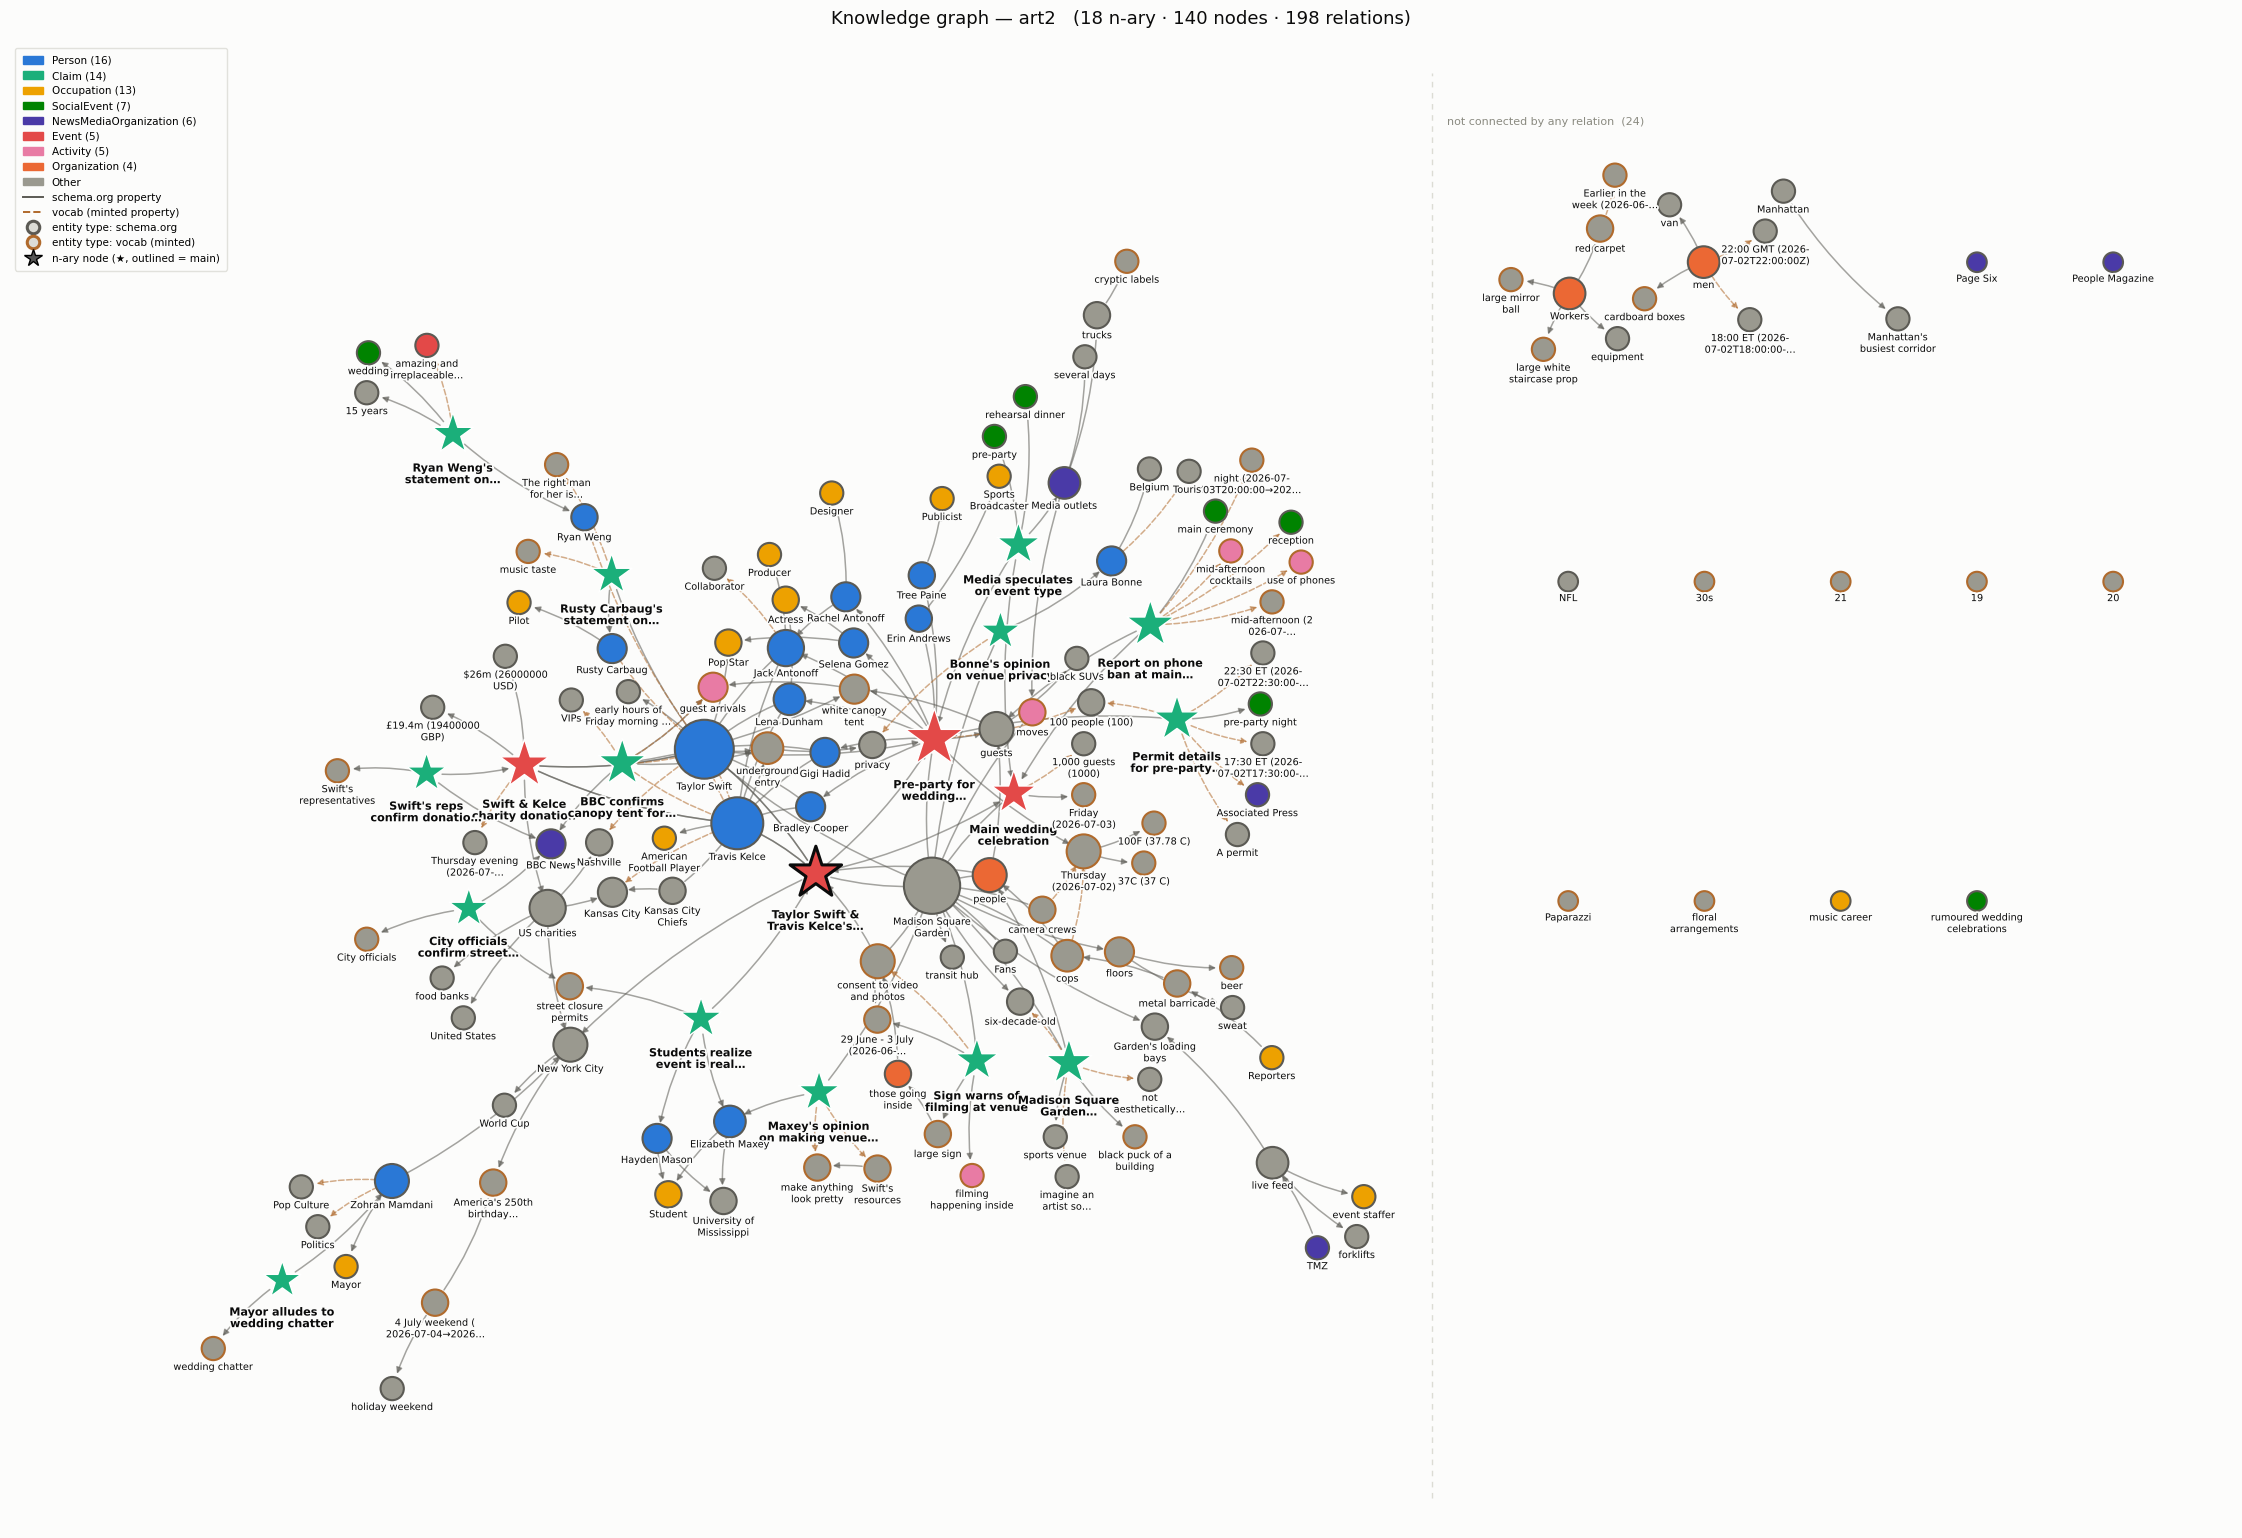

In [76]:
import math, textwrap
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import networkx as nx

# --- static-figure knobs (the interactive viewer has its own, in the cell below) ------------
LABEL_WRAP      = 16     # characters per line before wrapping a node label
LABEL_MAX_LINES = 2      # wrapped lines kept (the rest is elided with …)
LABEL_FONT      = 7.0    # node label size (pt)
EDGE_LABEL_MAX  = 110    # auto edge labels: drawn only when the graph has <= this many edges
DEOVERLAP_STEPS = 400    # label-aware separation passes; 0 disables

def kg_stem(aid, nodes=None):
    """Output basename keyed to the SOURCE file (LAST_SRC), so different views don't clobber each other:
         *_e2e      — single-call baseline  (nary_graph_e2e*.json, nb6c)
         *_reified  — staged event-centric  (nary_graph*.json / reified / hubs, nb6b/nb7b)
         kg_<id>    — binary triples        (relations_ext*.json, nb7)"""
    s = LAST_SRC
    if "e2e" in s:
        return "e2e/viz/kg"
    if any(t in s for t in ("nary_graph", "reified", "hubs")):
        return "two_staged/viz/kg_reified"
    return "two_staged/viz/kg_binary"

def _lbl(n):
    """Wrapped, length-capped node label (multi-line labels pack far tighter than one long line)."""
    s = n["label"] + (f' ({n["norm"]})' if (SHOW_NORMALIZED_TIME and n.get("norm")) else "")
    lines = textwrap.wrap(s, LABEL_WRAP) or [s]
    if len(lines) > LABEL_MAX_LINES:
        lines = lines[:LABEL_MAX_LINES]
        lines[-1] = lines[-1][:LABEL_WRAP - 1] + "…"
    return "\n".join(lines)

def _fit(pos, xr, yr):
    """Rescale a layout into the box xr × yr (keeps aspect, centres what's left over)."""
    if not pos: return pos
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    dx = (max(xs) - min(xs)) or 1.0; dy = (max(ys) - min(ys)) or 1.0
    s  = min((xr[1] - xr[0]) / dx, (yr[1] - yr[0]) / dy)
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    tx, ty = (xr[0] + xr[1]) / 2, (yr[0] + yr[1]) / 2
    return {i: ((p[0] - cx) * s + tx, (p[1] - cy) * s + ty) for i, p in pos.items()}

def _packed_layout(G, seed=None):
    """Spring-lay-out the giant component, and pack every OTHER component (mostly the isolated
    entities that no relation ever used) into a tidy grid in a side panel — instead of letting them
    ring the figure and squeeze the part that carries the information.
    Returns (pos, split_x) where split_x is the x of the divider, or None if there's no side panel."""
    seed = LAYOUT_SEED if seed is None else seed
    UG = G.to_undirected()
    comps = sorted(nx.connected_components(UG), key=len, reverse=True)
    if not comps:
        return {}, None
    main = comps[0]
    pos = nx.spring_layout(UG.subgraph(main), seed=seed, iterations=350,
                           k=2.6 / max(len(main) ** 0.5, 1))
    rest = comps[1:]
    if not rest:
        return _fit(pos, (-1, 1), (-1, 1)), None
    # the side panel is only as wide as it needs to be, so a graph with 3 loose nodes doesn't
    # give away a third of the figure to whitespace
    cols = max(1, round(math.sqrt(len(rest) * 1.9)))
    rows = math.ceil(len(rest) / cols)
    x1 = 1.30
    x0 = x1 - min(0.90, max(0.22, 0.19 * cols))
    y0, y1 = -0.95, 0.95
    pos = _fit(pos, (-1.30, x0 - 0.18), (-1.0, 1.0))              # connected graph keeps the left
    cw = (x1 - x0) / cols
    ch = min((y1 - y0) / max(rows, 1), 0.42)      # a few loose nodes shouldn't span the whole height
    for k, c in enumerate(rest):
        cx = x0 + cw * (k % cols) + cw / 2
        cy = y1 - ch * (k // cols) - ch / 2
        if len(c) == 1:
            pos[next(iter(c))] = (cx, cy)
        else:
            sub = nx.spring_layout(UG.subgraph(c), seed=seed, k=0.9)
            pos.update(_fit(sub, (cx - cw * 0.42, cx + cw * 0.42), (cy - ch * 0.42, cy + ch * 0.42)))
    return pos, x0 - 0.09

def _deoverlap(pos, boxes, steps=DEOVERLAP_STEPS):
    """Push nodes apart until their marker+label boxes stop intersecting.
    boxes = {id: (halfw, up, down)} in data units — asymmetric, because the label hangs BELOW
    the marker. Same idea as the interactive viewer's Tidy button, and it buys most of the
    legibility on the crowded 150-node graphs."""
    if steps <= 0 or len(pos) < 2:
        return pos
    ids = list(pos)
    P = {i: list(pos[i]) for i in ids}
    for _ in range(steps):
        moved = 0
        for a in range(len(ids)):
            for b in range(a + 1, len(ids)):
                ia, ib = ids[a], ids[b]
                (wa, ua, da), (wb, ub, db) = boxes[ia], boxes[ib]
                xa, ya = P[ia]; xb, yb = P[ib]
                ox = (wa + wb) - abs(xb - xa)
                oy = min(ya + ua, yb + ub) - max(ya - da, yb - db)
                if ox > 0 and oy > 0:
                    moved += 1
                    if ox < oy:
                        push = (ox / 2 + 1e-4) * (1 if xb >= xa else -1)
                        P[ia][0] -= push; P[ib][0] += push
                    else:
                        push = (oy / 2 + 1e-4) * (1 if yb >= ya else -1)
                        P[ia][1] -= push; P[ib][1] += push
        if not moved:
            break
    return {i: tuple(P[i]) for i in ids}

def draw_static(aid, nodes, edges, show_edge_labels=None, save=True, show=True):
    """PNG snapshot of the graph. `show_edge_labels=None` -> auto (labels only on small graphs)."""
    G = nx.MultiDiGraph()
    for i, n in nodes.items():
        G.add_node(i, **{k: v for k, v in n.items() if k != "raw"})
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            G.add_edge(e["s"], e["o"], property=e["property"], source=e["source"])
    if show_edge_labels is None:
        show_edge_labels = SHOW_EDGE_LABELS and len(edges) <= EDGE_LABEL_MAX

    deg = dict(G.degree())
    n_nary = sum(1 for i in nodes if nodes[i].get("is_nary"))
    # figure grows with the graph so density (and therefore label crowding) stays roughly constant
    scale  = min(2.0, max(1.0, (len(G) / 70) ** 0.42))
    figw, figh = STATIC_FIGSIZE[0] * scale, STATIC_FIGSIZE[1] * scale

    def kind(i):
        n = nodes[i]
        return "nary" if n.get("is_nary") else ("lit" if n.get("is_lit") else "ent")
    BASE_SIZE = {"ent": 200, "nary": 640, "lit": 130}
    def area(i):  return BASE_SIZE[kind(i)] + 80 * deg.get(i, 0)   # matplotlib marker area, pt²

    pos, split_x = _packed_layout(G)
    # marker + label extents in DATA units, so overlap resolution knows how big things really are
    span_x = (max(p[0] for p in pos.values()) - min(p[0] for p in pos.values())) or 1.0
    upt    = span_x / (figw * 72 * 0.90)                           # data units per typographic point
    boxes, radius = {}, {}
    for i in G.nodes():
        ls = _lbl(nodes[i]).split("\n")
        fs = LABEL_FONT * (1.15 if nodes[i].get("is_nary") else 1.0)
        r  = math.sqrt(area(i) / math.pi) * (1.25 if kind(i) == "nary" else 1.0)
        radius[i] = r * upt
        lw = max(len(x) for x in ls) * fs * 0.56
        lh = len(ls) * fs * 1.22
        boxes[i] = (max(lw / 2, r) * upt + 1.5 * upt,              # half width
                    r * upt + 1.0 * upt,                           # up  (marker only)
                    (r + lh) * upt + 2.0 * upt)                    # down (marker + label)
    pos = _deoverlap(pos, boxes)

    fig, ax = plt.subplots(figsize=(figw, figh))
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE); ax.axis("off")

    # edges first, so nodes and labels sit on top of them
    for bucket, (color, style) in EDGE_STYLE.items():
        elist = [(u, v) for u, v, d in G.edges(data=True) if edge_bucket(d.get("source")) == bucket]
        if elist:
            nx.draw_networkx_edges(
                G, pos, ax=ax, edgelist=elist, edge_color=color, style=style,
                width=1.1, alpha=0.55, arrows=True, arrowsize=9,
                connectionstyle="arc3,rad=0.09", node_size=500)

    # nodes grouped by kind so n-ary nodes (star) and literals (square) get their own marker & size
    for grp, marker in (("ent", "o"), ("nary", "*"), ("lit", "s")):
        ids = [i for i in G.nodes() if kind(i) == grp]
        if not ids:
            continue
        if grp == "ent":                                           # entity border = TYPE SOURCE; width = is_main
            ecolors = [type_src_border(nodes[i].get("type_source")) for i in ids]
            widths  = [2.6 if nodes[i].get("is_main") else 1.5 for i in ids]
        else:                                                      # n-ary / literal: border just marks is_main
            ecolors = [INK if nodes[i].get("is_main") else "white" for i in ids]
            widths  = [2.2 if nodes[i].get("is_main") else 1.0 for i in ids]
        nx.draw_networkx_nodes(
            G, pos, ax=ax, nodelist=ids, node_shape=marker,
            node_color=[node_color(nodes[i]["type"]) for i in ids],
            node_size=[area(i) for i in ids],
            edgecolors=ecolors, linewidths=widths)

    # labels hang just under their marker, with a surface-coloured halo so they read over edges
    for i in G.nodes():
        ax.text(pos[i][0], pos[i][1] - radius[i] - 0.8 * upt, _lbl(nodes[i]), ha="center", va="top",
                fontsize=LABEL_FONT * (1.15 if nodes[i].get("is_nary") else 1.0),
                fontweight="bold" if nodes[i].get("is_nary") else "normal",
                color=INK, zorder=5,
                path_effects=[pe.withStroke(linewidth=2.6, foreground=SURFACE)])

    if show_edge_labels:
        agg = {}                                                   # aggregate parallel edges' labels per (u,v)
        for u, v, d in G.edges(data=True):
            agg.setdefault((u, v), []).append(d.get("property") or "")
        nx.draw_networkx_edge_labels(
            G, pos, ax=ax, font_size=LABEL_FONT - 1.2, font_color="#4a4a44", rotate=False,
            bbox=dict(boxstyle="round,pad=0.12", fc=SURFACE, ec="none", alpha=0.75),
            edge_labels={k: ", ".join(dict.fromkeys(v)) for k, v in agg.items()})

    if split_x is not None:                                        # divider + caption for the side panel
        ymin = min(p[1] for p in pos.values()); ymax = max(p[1] for p in pos.values())
        n_side = sum(1 for i, p in pos.items() if p[0] > split_x)
        ax.axvline(split_x, ymin=0.02, ymax=0.98, color="#dcdcd4", lw=1.0, ls=(0, (4, 4)), zorder=0)
        ax.text(split_x + 0.02, ymax + 0.04 * (ymax - ymin),
                f"not connected by any relation  ({n_side})", fontsize=8, color="#8a8a80", va="bottom")

    handles = [mpatches.Patch(color=c, label=f"{t} ({type_counts[t]})") for t, c in TYPE_COLORS.items()]
    if HAS_OTHER:
        handles.append(mpatches.Patch(color=OTHER_COLOR, label="Other"))
    # only show edge-source legend entries that actually occur in this graph
    present = {edge_bucket(e["source"]) for e in edges}
    edge_legend = [("open", OPEN_EDGE, "-", "open (not yet canonicalized)"),
                   ("schema.org", SCHEMA_EDGE, "-", "schema.org property"),
                   ("vocab", EX_EDGE, "--", "vocab (minted property)")]
    handles += [plt.Line2D([0], [0], color=col, lw=1.4, ls=ls, label=lab)
                for b, col, ls, lab in edge_legend if b in present]
    # entity TYPE-SOURCE ring legend (node border colour) — only buckets that occur
    present_tsrc = {type_src_bucket(nodes[i].get("type_source"))
                    for i in nodes if not nodes[i].get("is_nary") and not nodes[i].get("is_lit")}
    tsrc_legend = [("schema.org", SCHEMA_EDGE, "entity type: schema.org"),
                   ("vocab", EX_EDGE, "entity type: vocab (minted)"),
                   ("open", OPEN_EDGE, "entity type: open (free-form)")]
    handles += [plt.Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="#dcdcd6",
                           markeredgecolor=col, markeredgewidth=2.2, markersize=9, label=lab)
                for b, col, lab in tsrc_legend if b in present_tsrc]
    if n_nary:
        handles.append(plt.Line2D([0], [0], marker="*", color="none", markerfacecolor="#555",
                                   markersize=13, label="n-ary node (★, outlined = main)"))
        subtitle = f"{n_nary} n-ary · {len(nodes) - n_nary} nodes · {len(edges)} relations"
    else:
        subtitle = f"{len(nodes)} entities · {len(edges)} relations"
    leg = ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 1.0), fontsize=7.5,
                    frameon=True, facecolor=SURFACE, edgecolor="#e0e0da", framealpha=0.94,
                    borderpad=0.7, labelspacing=0.5)
    leg.set_zorder(10)
    ax.set_title(f"Knowledge graph — {aid}   ({subtitle})", fontsize=13, color=INK, pad=14)
    ax.margins(0.06)
    fig.tight_layout()

    if save:
        out = RESULTS_DIR / aid / f"{kg_stem(aid, nodes)}.png"; out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out, dpi=170, facecolor=SURFACE, bbox_inches="tight")
        print("saved", out)
    if show:
        plt.show()
    else:
        plt.close(fig)

draw_static(ARTICLE_ID, nodes, edges)

## 4. Interactive viewer → `results/<id>/<track>/viz/kg.html`

One **self-contained** HTML file (vis-network inlined, opens offline) rendered by
`notebooks/kg_viz.py`. What it adds over a plain graph dump:

**Filters** (left panel, everything live). **Filtered out → Fade / Hide**: by default whatever a
filter excludes stays on the canvas as a ghost — a **Ghost opacity** slider (default 35%) sets how
faint — so the layout never jumps and you keep the context; switch to *Hide* to remove it outright.
(The Structure options below always remove.)

- **Vocabulary source** — separately for *relations* and for *node types*: `schema.org` /
  `minted (ex:)` / `open (not yet canonicalized)`. Untick "schema.org" under relations and you are
  looking at exactly what the pipeline had to mint.
- **Node types** — checkbox per type with counts (All / None / Top 8).
- **Structure** — show/hide n-ary nodes, entities, literals; hide isolated nodes; hide leaf entities
  (degree 1 — the single biggest hairball reducer); *main event's neighbourhood only*; minimum confidence.

**Colour by** — `Entity type` (hue = type, ring = where the type came from) · `Vocabulary`
(hue = schema.org vs minted vs open, for nodes *and* edges) · `Node kind` (Event / Observation / Claim / entity).

**Overlap control** — physics settles once then freezes, followed by a label-aware *de-overlap* pass
(also on the **Tidy** button); a **Spacing** slider; edge labels default to *on select* instead of
always; and three layouts: force-directed, **concentric** (n-ary nodes on an inner ring, their
entities sorted next to them on the outer rings — deterministic and crossing-light), and hierarchical.

**Inspection** — **hover** shows the term's parent and its full path
(`Thing › Intangible › StructuredValue › DateRange*`, `*` = minted); **click** a node or edge for its
full record — the path as a colour-coded breadcrumb, plus definition, justification, confidence and the
evidence quote. Double-click a node to isolate its neighbourhood;
`/` to search; **Triples** opens a filter-synced subject–property–object table (copyable as TSV);
**PNG** downloads the current view; ◐ toggles dark mode.


In [77]:
# The viewer itself lives in notebooks/kg_viz.py (a few hundred lines of HTML/JS); this cell just
# feeds it the loaded graph, this notebook's colour map, and the term-path resolvers from §2b.
# Edit kg_viz.py and re-run — importlib.reload picks the changes up without restarting the kernel.
import sys, pathlib, importlib
for _p in (pathlib.Path.cwd(), *pathlib.Path.cwd().parents):
    if (_p / "kg_viz.py").exists():
        sys.path.insert(0, str(_p)); break
import kg_viz; importlib.reload(kg_viz)

IFRAME_HEIGHT = "820px"           # inline preview height in the notebook (the file itself is full-screen)

def draw_interactive(aid, nodes, edges, save=True, show=True):
    """Write results/<aid>/<track>/viz/kg.html — one offline file with filters, layouts and details."""
    out = RESULTS_DIR / aid / f"{kg_stem(aid, nodes)}.html"
    build_paths()                 # pick the minted vocabulary matching the graph variant just loaded
    kg_viz.write_html(
        out, aid, nodes, edges,
        type_colors=TYPE_COLORS, other_color=OTHER_COLOR,
        theme={"schema": SCHEMA_EDGE, "vocab": EX_EDGE, "open": OPEN_EDGE},
        source_file=pathlib.Path(LAST_SRC).name,
        title=f"Knowledge graph — {aid} ({RESULTS_MODEL})",
        type_path=type_path, prop_path=prop_path,   # hover shows Thing › Event › SocialEvent
    )
    print("saved", out, f"({out.stat().st_size / 1e6:.1f} MB, self-contained)")
    if show:
        from IPython.display import IFrame, display
        display(IFrame(src=str(out), width="100%", height=IFRAME_HEIGHT))
    return out

draw_interactive(ARTICLE_ID, nodes, edges)

saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art2/e2e/viz/kg.html (0.8 MB, self-contained)


PosixPath('/Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art2/e2e/viz/kg.html')

## 5. Triples table (subject → property → object)

In [78]:
# Plain, sorted listing of every edge — the KG as text, for a quick read / copy.
def print_triples(nodes, edges):
    rows = sorted(edges, key=lambda e: (e.get("property") or "", nodes.get(e["s"], {}).get("label", "")))
    print(f"{len(rows)} relations\n" + "-" * 90)
    for e in rows:
        s = nodes.get(e["s"], {}).get("label", e.get("s_text") or e["s"])
        o = nodes.get(e["o"], {}).get("label", e.get("o_text") or e["o"])
        tag = edge_bucket(e["source"])                             # open / schema.org / vocab
        conf = f'  ({e["confidence"]})' if e.get("confidence") is not None else ""
        print(f'  {s}  --{e["property"]} [{tag}]-->  {o}{conf}')

print_triples(nodes, edges)

198 relations
------------------------------------------------------------------------------------------
  BBC confirms canopy tent for guest arrivals  --about [schema.org]-->  white canopy tent  (1.0)
  BBC confirms canopy tent for guest arrivals  --about [schema.org]-->  guest arrivals  (1.0)
  Bonne's opinion on venue privacy  --about [schema.org]-->  Madison Square Garden  (1.0)
  City officials confirm street closure permit application  --about [schema.org]-->  street closure permits  (1.0)
  Madison Square Garden unexpected venue for Swift  --about [schema.org]-->  Madison Square Garden  (1.0)
  Maxey's opinion on making venue look pretty  --about [schema.org]-->  Madison Square Garden  (1.0)
  Mayor alludes to wedding chatter  --about [schema.org]-->  wedding chatter  (1.0)
  Media speculates on event type  --about [schema.org]-->  Pre-party for wedding celebrations  (1.0)
  Media speculates on event type  --about [schema.org]-->  Main wedding celebration  (1.0)
  Media speculat

## 6. Batch — render every article

In [79]:
# Render the static PNG (and interactive HTML) for every article that has an nb7 relations file.
# No inline display — just writes results/<id>/kg_<id>.png and .html.
_articles = sorted({p.relative_to(RESULTS_DIR).parts[0] for name in REL_FILES for p in RESULTS_DIR.glob(f"*/{name}")})
print("rendering", len(_articles), "article(s):", _articles)
for aid in _articles:
    n, e, _ = load_kg(aid)
    if not n:
        print(f"  {aid}: no connected entities, skipped"); continue
    # rebuild the per-article type colour map so each figure is self-consistent
    global TYPE_COLORS, HAS_OTHER, type_counts
    type_counts = Counter(v["type"] for v in n.values())
    TYPE_COLORS, HAS_OTHER = build_type_colors(n)
    draw_static(aid, n, e, save=True, show=False)
    draw_interactive(aid, n, e, save=True, show=False)
print("done")

rendering 4 article(s): ['art1', 'art2', 'art4', 'art5']
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art1/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art1/e2e/viz/kg.html (0.7 MB, self-contained)
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art2/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art2/e2e/viz/kg.html (0.8 MB, self-contained)
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art4/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/gemini-2.5-flash/art4/e2e/viz/kg.html (0.6 MB, self-contained)
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/P